# AI-Driven Dual-Module System for Coated-Fertilizer Nutrient Release & Crop Recommendations
**CSI3001 Data Science Programming** · Amit Kumar (24MID0155) · Mohammad Afaan Sherief (24MID0178) · Bhumi Kumari (24MID0216)

This notebook walks through the full project following the methodology in the review deck:

1. **Data generation**: real field data + simulated coated-fertilizer release
2. **Train Module 1**: nutrient release prediction (Linear Regression / Decision Tree)
3. **Train Module 2**: fertilizer recommendation (Random Forest / XGBoost)
4. **Pipeline integration**: Module 1's predicted release rate feeds Module 2
5. **Evaluate & test**: 80/20 split, MSE / R² / accuracy, comparison with today's static system, and user inputs

All logic lives in `src/`; this notebook calls it and shows the results.

In [1]:
import sys, json, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
sys.path.insert(0, str(Path.cwd() / "src"))

import numpy as np, pandas as pd
from IPython.display import Image, display
pd.set_option("display.precision", 3)

from config import CROP_DATA, CROP_REQ_DATA, RELEASE_DATA, RECOMMEND_DATA, FIG_DIR, OUTPUT_DIR
import release_physics as phys
import generate_dataset, eda, train_module1, train_module2
from pipeline import SmartFertilizerSystem
fig = lambda name: display(Image(filename=str(FIG_DIR / name)))

## 1. Data

### 1a. Real field data
The Kaggle **Crop Recommendation Dataset** gives 2,200 real field records (22 crops, 100 each) with soil N, P, K, pH and
climate. A crop-wise N-P-K requirement table gives the agronomic targets.

In [2]:
fields = pd.read_csv(CROP_DATA)
print(fields.shape); display(fields.head())
display(fields.describe().T)
display(pd.read_csv(CROP_REQ_DATA).head())

(2200, 8)


,N,P,K,temperature,humidity,ph,rainfall,label
0,90,42,43,20.880,82.003,6.503,202.936,rice
1,85,58,41,21.770,80.320,7.038,226.656,rice
2,60,55,44,23.004,82.321,7.840,263.964,rice
3,74,35,40,26.491,80.158,6.980,242.864,rice
4,78,42,42,20.130,81.605,7.628,262.717,rice


,count,mean,std,min,25%,50%,75%,max
N,2200.0,50.552,36.917,0.000,21.000,37.000,84.250,140.000
P,2200.0,53.363,32.986,5.000,28.000,51.000,68.000,145.000
K,2200.0,48.149,50.648,5.000,20.000,32.000,49.000,205.000
temperature,2200.0,25.616,5.064,8.826,22.769,25.599,28.562,43.675
humidity,2200.0,71.482,22.264,14.258,60.262,80.473,89.949,99.982
ph,2200.0,6.469,0.774,3.505,5.972,6.425,6.924,9.935
rainfall,2200.0,103.464,54.958,20.211,64.552,94.868,124.268,298.560


,Crop,N,P,K,pH,soil_moisture
0,rice,80,40,40,5.5,30
1,maize,80,40,20,5.5,50
2,chickpea,40,60,80,5.5,60
3,kidneybeans,20,60,20,5.5,45
4,pigeonpeas,20,60,20,5.5,45


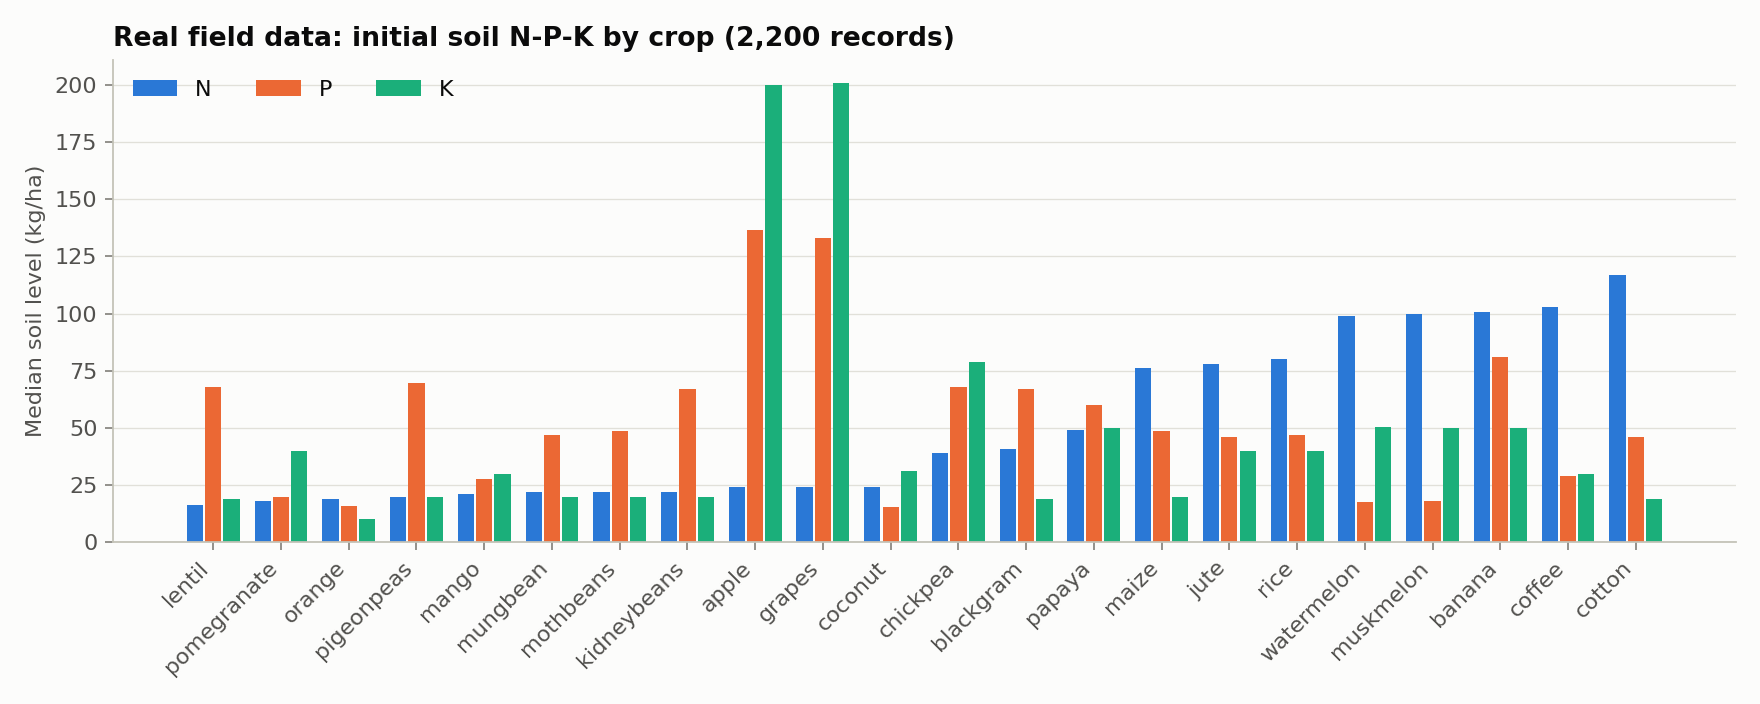

In [3]:
eda.plots.apply_style(); eda.real_data_overview(); fig("real_data_npk_by_crop.png")

### 1b. Why we simulate release
No public dataset measures coated-fertilizer release under field weather. Instead we use relationships reported in the
literature (`src/release_physics.py`):

- **Temperature:** Q10 = 1.8, so each +10 °C roughly halves release time (Brown et al. 1966; Kassem et al. 2024).
- **Coating thickness:** rated duration grows with thickness (≈90 days at 65 µm, rated at 25 °C).
- **Moisture and rainfall:** dry soil slows release; heavy rain speeds it slightly.
- **pH:** only a weak effect.
- **Curve shape:** cumulative release follows a sigmoidal Weibull curve.

In [4]:
for label, T, M, R in [("lab 25 °C", 25, 30, 100), ("hot & wet 35 °C", 35, 40, 220), ("cool & dry 18 °C", 18, 12, 40)]:
    print(f"'90-day' coated urea, {label:<17}: 80% released after {phys.effective_duration(65, T, M, R, 6.5):6.1f} days")

'90-day' coated urea, lab 25 °C        : 80% released after   90.0 days
'90-day' coated urea, hot & wet 35 °C  : 80% released after   44.0 days
'90-day' coated urea, cool & dry 18 °C : 80% released after  172.8 days


### 1c. Generate the two datasets
Each real record is expanded into 5 season scenarios, giving 11,000 rows per module.

In [5]:
generate_dataset.main()
release = pd.read_csv(RELEASE_DATA); recommend = pd.read_csv(RECOMMEND_DATA)
display(release.head()); display(recommend.head())

Real field records: 2,200 (22 crops)
Module 1 dataset -> nutrient_release_dataset.csv: (11000, 11)
Module 2 dataset -> fertilizer_recommendation_dataset.csv: (11000, 14)

Fertilizer class balance:
fertilizer_type
NPK 19-19-19            3798
Urea (uncoated)         2048
MOP (0-0-60)            2037
PCU-120 (thick coat)    1103
DAP (18-46-0)            926
PCU-60 (thin coat)       590
PCU-90 (standard)        498


,crop_type,soil_temperature,soil_moisture,rainfall,coating_thickness,soil_pH,days_since_application,rated_duration,effective_duration,release_rate,cumulative_release
0,rice,26.744,36.089,199.258,95.145,6.267,41,129.188,109.228,0.737,25.306
1,rice,23.569,36.509,194.517,47.893,6.570,37,67.761,68.449,1.219,42.290
2,rice,26.227,34.664,188.520,61.493,6.512,74,85.441,63.445,1.244,89.734
3,rice,23.726,34.084,213.674,73.197,6.511,26,100.656,91.207,0.844,16.765
4,rice,20.334,35.208,169.138,30.908,6.575,16,45.681,57.282,1.403,14.004


,crop_type,growth_stage,N,P,K,soil_pH,soil_temperature,soil_moisture,rainfall,reference_release_rate,field_rate_factor,fertilizer_type,fertilizer_amount,application_timing
0,rice,sowing,90,42,43,6.477,22.113,41.355,254.942,0.893,1.005,NPK 19-19-19,524.8,31
1,rice,vegetative,90,42,43,6.447,25.685,37.471,236.949,1.028,1.157,NPK 19-19-19,322.9,25
2,rice,maturity,90,42,43,6.591,22.791,37.230,272.154,0.917,1.032,NPK 19-19-19,72.7,20
3,rice,sowing,90,42,43,6.537,21.261,37.701,189.517,0.828,0.931,NPK 19-19-19,453.0,32
4,rice,maturity,90,42,43,6.434,22.840,35.453,176.332,0.904,1.017,NPK 19-19-19,67.1,17


In [6]:
release.describe().T

,count,mean,std,min,25%,50%,75%,max
soil_temperature,11000.0,29.137,5.477,8.113,25.742,29.153,32.354,48.000
soil_moisture,11000.0,27.973,6.950,5.456,23.571,28.161,32.660,50.000
rainfall,11000.0,104.894,58.480,15.800,62.101,92.940,132.659,431.954
coating_thickness,11000.0,60.342,23.079,20.001,40.661,60.353,80.529,99.973
soil_pH,11000.0,6.468,0.780,3.500,5.966,6.427,6.925,9.900
days_since_application,11000.0,75.206,43.517,0.000,37.000,75.000,113.000,150.000
rated_duration,11000.0,83.945,30.003,31.501,58.359,83.959,110.188,135.465
effective_duration,11000.0,69.594,36.301,7.962,42.518,63.390,88.216,349.487
release_rate,11000.0,1.515,0.905,0.227,0.908,1.256,1.879,10.383
cumulative_release,11000.0,68.780,34.351,0.000,40.905,85.137,98.509,100.000


### 1d. Exploratory analysis

[EDA] '90-day' coated urea real duration: median 70 d, 90% of fields 40–126 d


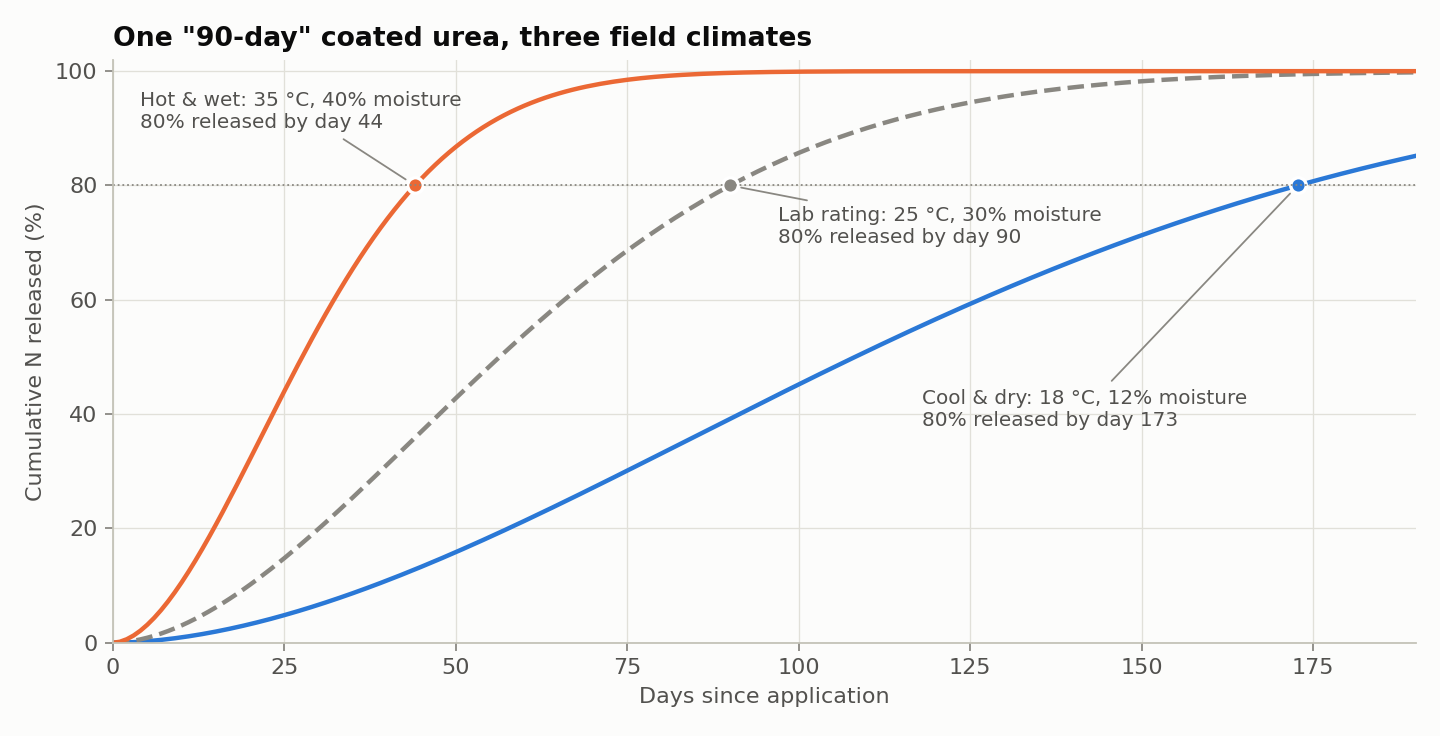

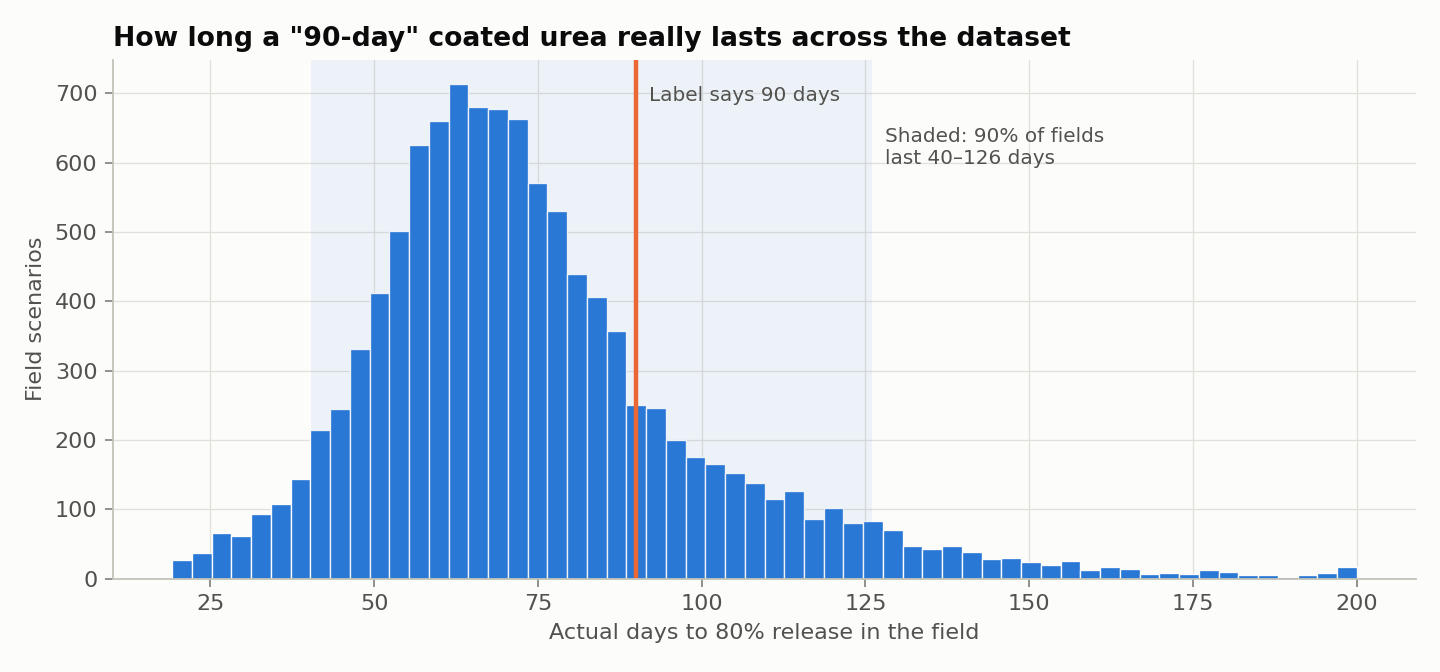

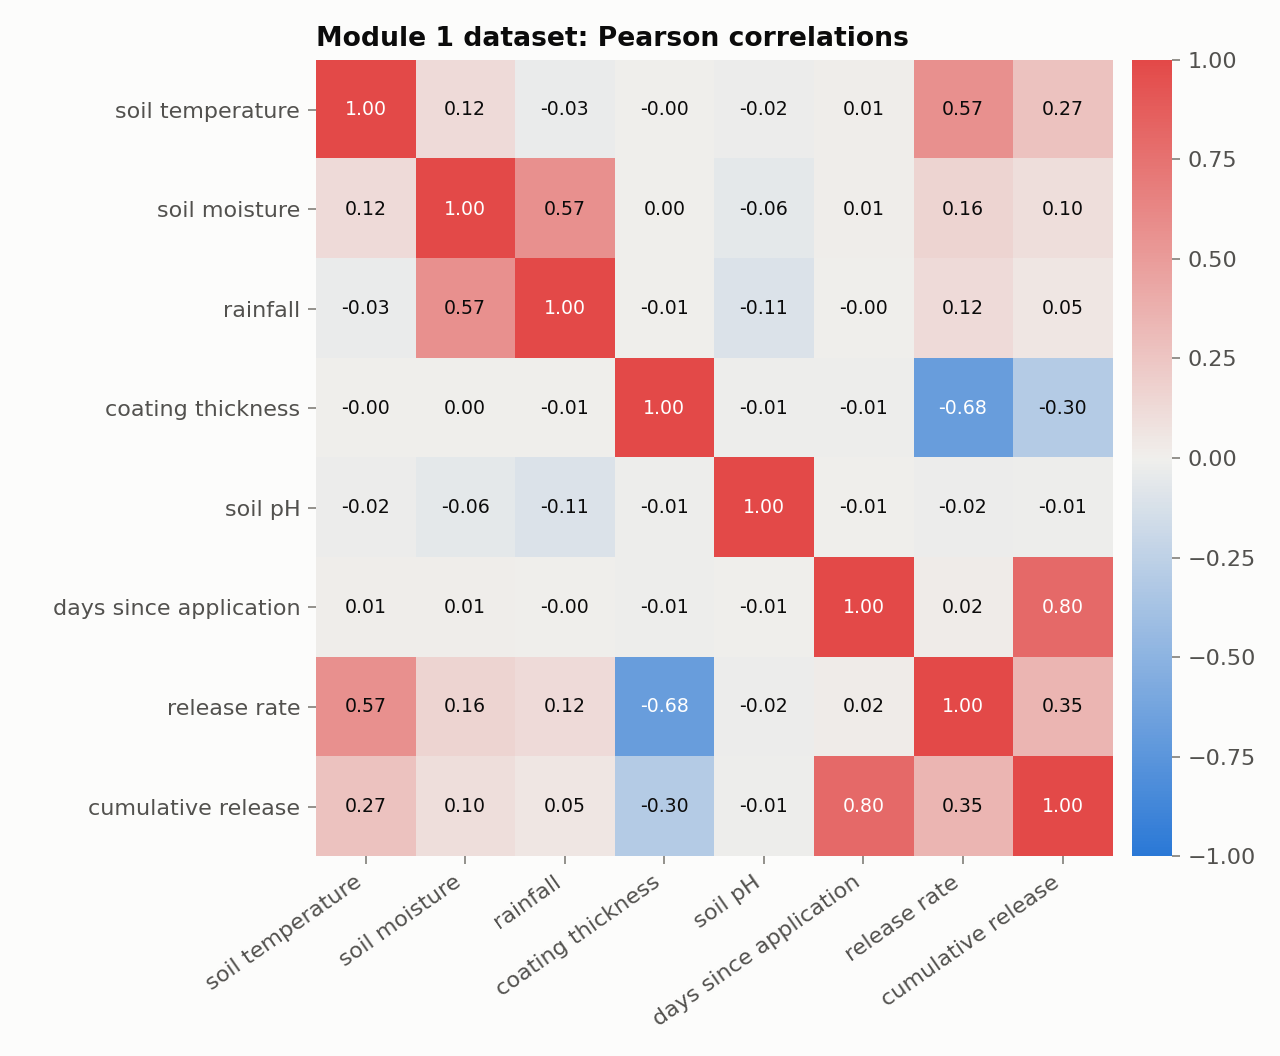

In [7]:
summary = eda.main()
fig("release_curves.png"); fig("duration_histogram.png"); fig("correlation_heatmap.png")

A "90-day" coated urea really lasts **40–126 days** across 90% of the fields. That is the unpredictability
the project sets out to fix. Release rate correlates strongly with coating thickness (−0.68) and soil temperature (+0.57).

## 2. Module 1: Nutrient release prediction
Targets: **release rate** (% per day) and **cumulative release** (% after *t* days). Models: Linear Regression,
polynomial Linear Regression, a grid-searched Decision Tree, and a Random Forest benchmark. We use an 80/20 split with
5-fold CV on the training set; the best model is chosen by CV R².

In [8]:
m1 = train_module1.main()
rows = [{"target": t, "model": n, **{k: v for k, v in r.items() if k != "best_params"}}
        for t in m1 for n, r in m1[t]["models"].items()]
display(pd.DataFrame(rows).set_index(["target", "model"]))
print({t: m1[t]["best"] for t in m1})


[Module 1] target = release_rate


  Linear Regression          test R2=0.8107  RMSE=0.3959  CV R2=0.8036±0.0058


  Polynomial LR (deg 3)      test R2=0.9814  RMSE=0.1240  CV R2=0.9793±0.0014


  Decision Tree              test R2=0.9600  RMSE=0.1819  CV R2=0.9554±0.0025


  Random Forest (benchmark)  test R2=0.9769  RMSE=0.1383  CV R2=0.9749±0.0021
  -> best: Polynomial LR (deg 3)

[Module 1] target = cumulative_release
  Linear Regression          test R2=0.8089  RMSE=15.0406  CV R2=0.7972±0.0085


  Polynomial LR (deg 3)      test R2=0.9600  RMSE=6.8848  CV R2=0.9599±0.0009


  Decision Tree              test R2=0.9657  RMSE=6.3760  CV R2=0.9664±0.0012


  Random Forest (benchmark)  test R2=0.9868  RMSE=3.9593  CV R2=0.9868±0.0005
  -> best: Random Forest (benchmark)


MSE    RMSE     MAE     R2  \
target             model                                                       
release_rate       Linear Regression            0.157   0.396   0.262  0.811   
                   Polynomial LR (deg 3)        0.015   0.124   0.087  0.981   
                   Decision Tree                0.033   0.182   0.120  0.960   
                   Random Forest (benchmark)    0.019   0.138   0.093  0.977   
cumulative_release Linear Regression          226.221  15.041  12.426  0.809   
                   Polynomial LR (deg 3)       47.401   6.885   5.385  0.960   
                   Decision Tree               40.653   6.376   4.110  0.966   
                   Random Forest (benchmark)   15.676   3.959   2.659  0.987   

                                              CV_R2_mean  CV_R2_std  
target             model                                             
release_rate       Linear Regression               0.804  5.783e-03  
                   Polynomial LR (deg 3)           0.979  1.387e-03  
                   Decision Tree                   0.955  2.539e-03  
                   Random Forest (benchmark)       0.975  2.080e-03  
cumulative_release Linear Regression               0.797  8.498e-03  
                   Polynomial LR (deg 3)           0.960  9.313e-04  
                   Decision Tree                   0.966  1.191e-03  
                   Random Forest (benchmark)       0.987  5.355e-04

{'release_rate': 'Polynomial LR (deg 3)', 'cumulative_release': 'Random Forest (benchmark)'}


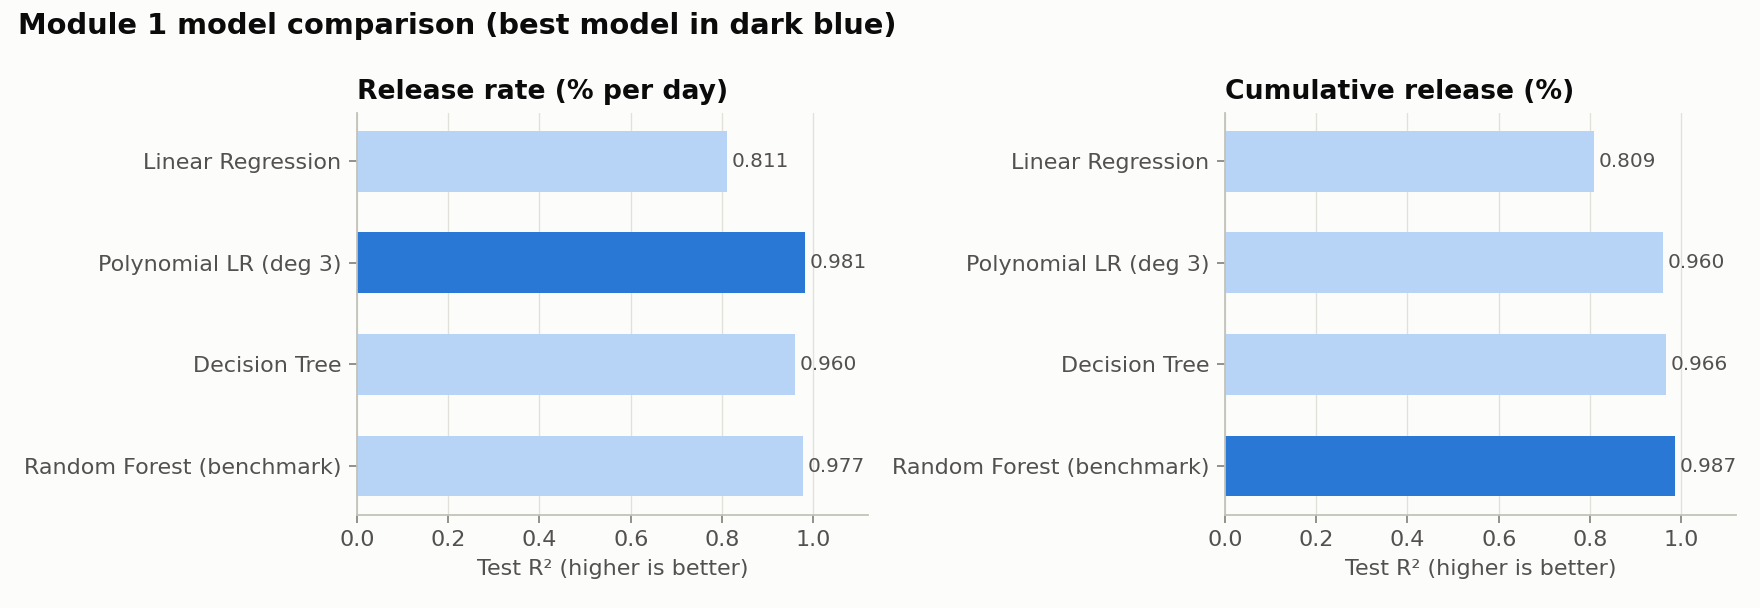

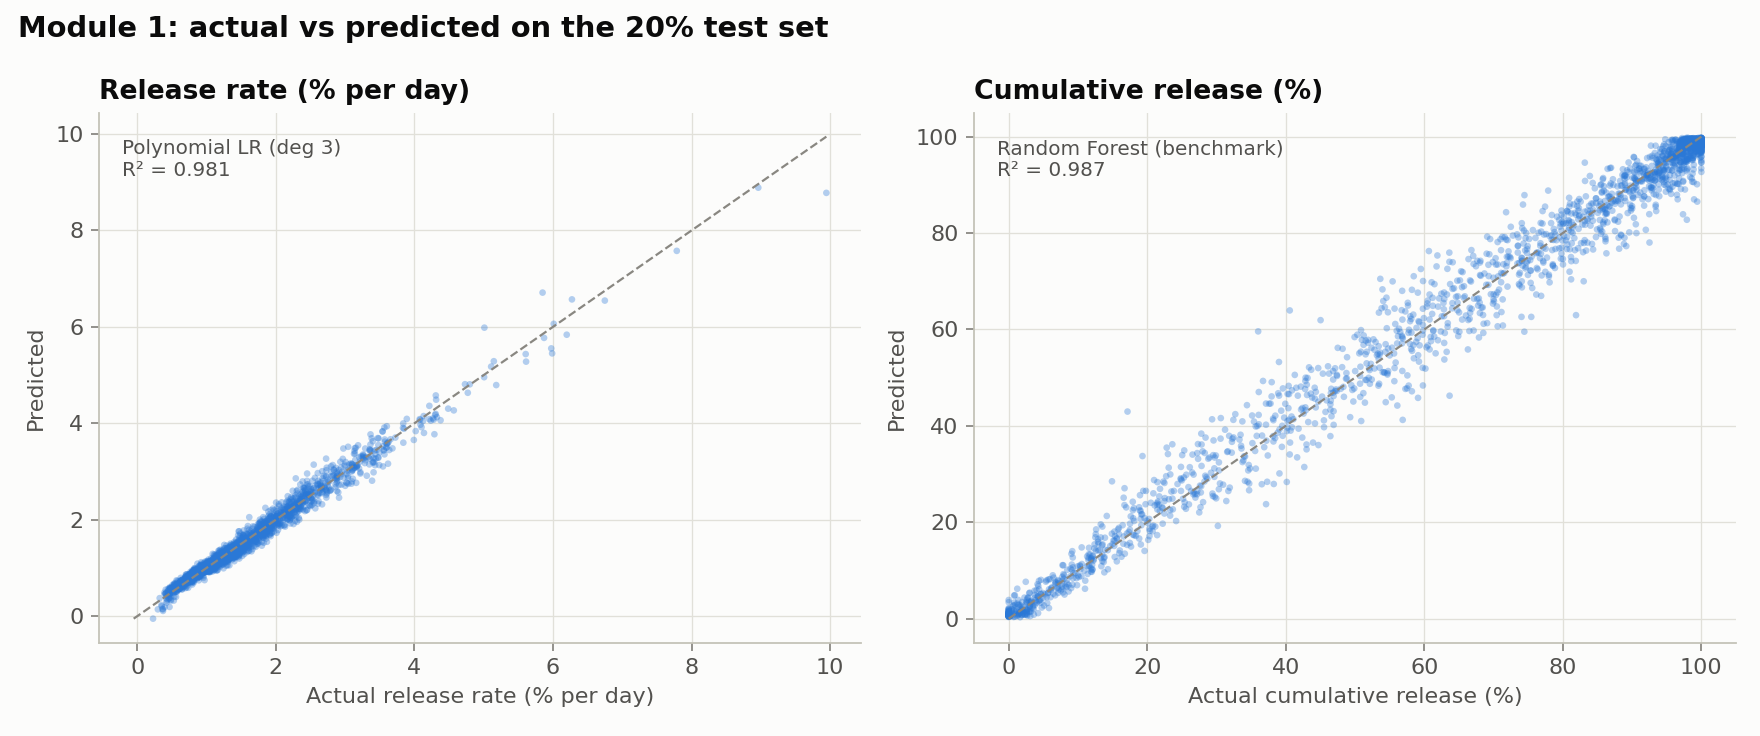

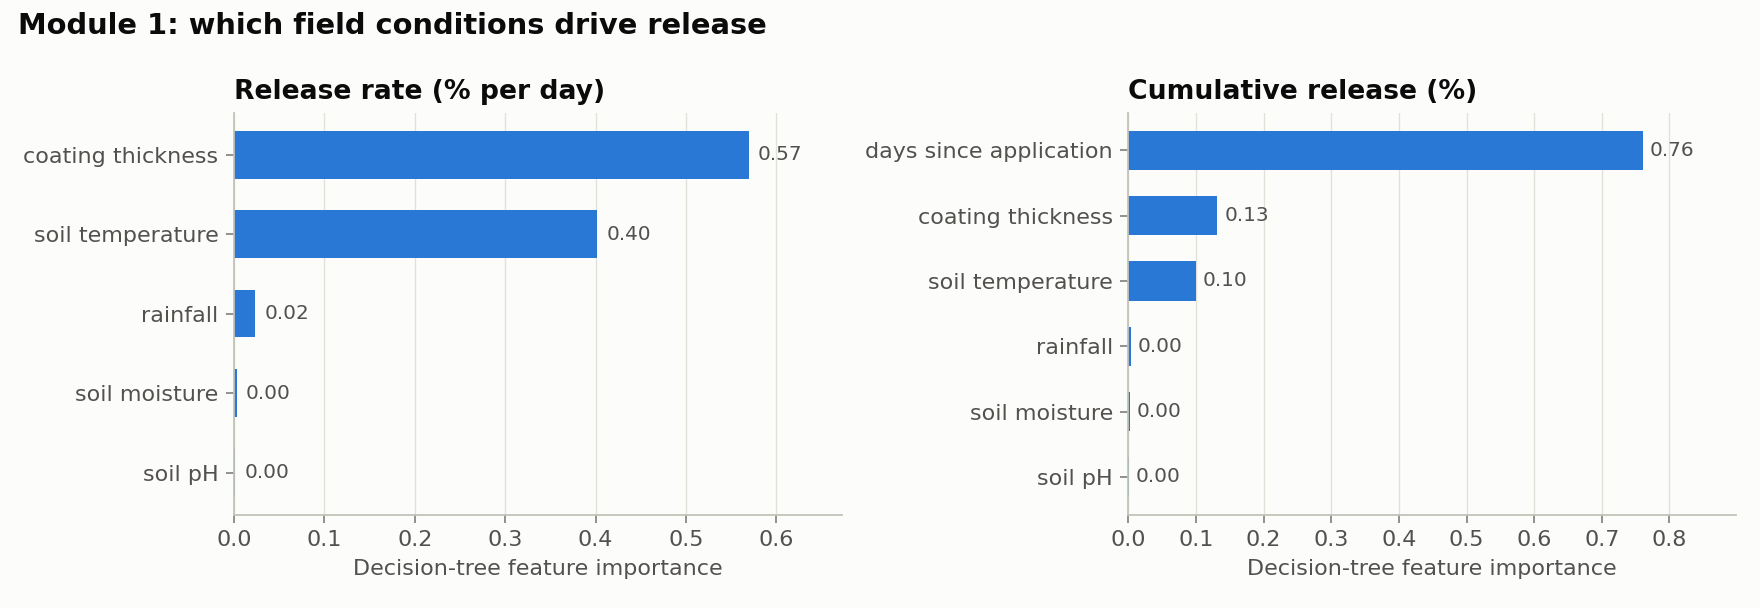

In [9]:
fig("m1_model_comparison.png"); fig("m1_actual_vs_predicted.png"); fig("m1_feature_importance.png")

Plain linear regression underfits (R² ≈ 0.81) because temperature acts exponentially. Polynomial terms and
trees capture this (R² ≈ 0.98–0.99). Coating thickness and soil temperature dominate feature importance.

## 3 & 4. Module 2 and pipeline integration
Module 2 receives Module 1's **predicted** release rate (not the true one), plus a synchrony index (predicted
release duration ÷ days of crop demand left), crop type, growth stage, initial N-P-K and soil pH.
It works in two steps: it first classifies the **fertilizer type**, then regresses the **amount** and **timing** for that
product. Models: a Decision Tree baseline, Random Forest and XGBoost.

In [10]:
m2 = train_module2.main()


[Module 2] boosting backend: XGBoost
  Module 1 -> Module 2 release-rate R2 vs truth: 0.9628

[Module 2] target = fertilizer_type


  Decision Tree (baseline)     acc=0.8041  macroF1=0.7862  CV acc=0.7970±0.0074  PCU-grade acc=0.7534


  Random Forest                acc=0.8300  macroF1=0.8112  CV acc=0.8185±0.0119  PCU-grade acc=0.7854


  XGBoost                      acc=0.8568  macroF1=0.8393  CV acc=0.8548±0.0094  PCU-grade acc=0.8037


  noise ceiling (exact rule on noisy labels): 0.8836
  -> best: XGBoost;  without Module 1: acc=0.8359  PCU-grade acc=0.7100

[Module 2] target = fertilizer_amount
  Decision Tree (baseline)     R2=0.9867  MAE=9.227  CV R2=0.9838±0.0027  end-to-end R2=0.7594


...

  XGBoost                      R2=0.9924  MAE=8.412  CV R2=0.9909±0.0015  end-to-end R2=0.7643


  -> best: XGBoost;  without Module 1: R2=0.9910

[Module 2] target = application_timing
  Decision Tree (baseline)     R2=0.9614  MAE=2.865  CV R2=0.9628±0.0015  end-to-end R2=0.8205


  Random Forest                R2=0.9728  MAE=2.435  CV R2=0.9756±0.0011  end-to-end R2=0.8322


  XGBoost                      R2=0.9760  MAE=2.383  CV R2=0.9770±0.0008  end-to-end R2=0.8336


  -> best: XGBoost;  without Module 1: R2=0.9039

[System comparison] MAE  (static | no-Module-1 | proposed)
  application_timing              9.22 | 4.42 | 2.38
  fertilizer_amount               12.62 | 8.97 | 8.41
  application_timing_coated_urea  22.36 | 8.45 | 3.97


In [11]:
t = m2["fertilizer_type"]
display(pd.DataFrame(t["models"]).T[["accuracy", "macro_F1", "CV_accuracy_mean", "coated_urea_accuracy"]])
print("Best:", t["best"], "| accuracy ceiling given label noise:", round(t["rule_ceiling_accuracy"], 3),
      "| without Module 1:", round(t["without_module1"]["accuracy"], 3))
for target in ["fertilizer_amount", "application_timing"]:
    df = pd.DataFrame({n: {**{k: v for k, v in r.items() if k != "end_to_end"},
                           "end_to_end_R2": r["end_to_end"]["R2"]} for n, r in m2[target]["models"].items()}).T
    print(f"\n{target}  (best: {m2[target]['best']})"); display(df[["R2", "MAE", "RMSE", "CV_R2_mean", "end_to_end_R2"]])

,accuracy,macro_F1,CV_accuracy_mean,coated_urea_accuracy
Decision Tree (baseline),0.804,0.786,0.797,0.753
Random Forest,0.830,0.811,0.819,0.785
XGBoost,0.857,0.839,0.855,0.804


Best: XGBoost | accuracy ceiling given label noise: 0.884 | without Module 1: 0.836

fertilizer_amount  (best: XGBoost)


,R2,MAE,RMSE,CV_R2_mean,end_to_end_R2
Decision Tree (baseline),0.987,9.227,19.228,0.984,0.759
Random Forest,0.992,7.786,15.057,0.990,0.763
XGBoost,0.992,8.412,14.531,0.991,0.764



application_timing  (best: XGBoost)


,R2,MAE,RMSE,CV_R2_mean,end_to_end_R2
Decision Tree (baseline),0.961,2.865,4.256,0.963,0.821
Random Forest,0.973,2.435,3.571,0.976,0.832
XGBoost,0.976,2.383,3.353,0.977,0.834


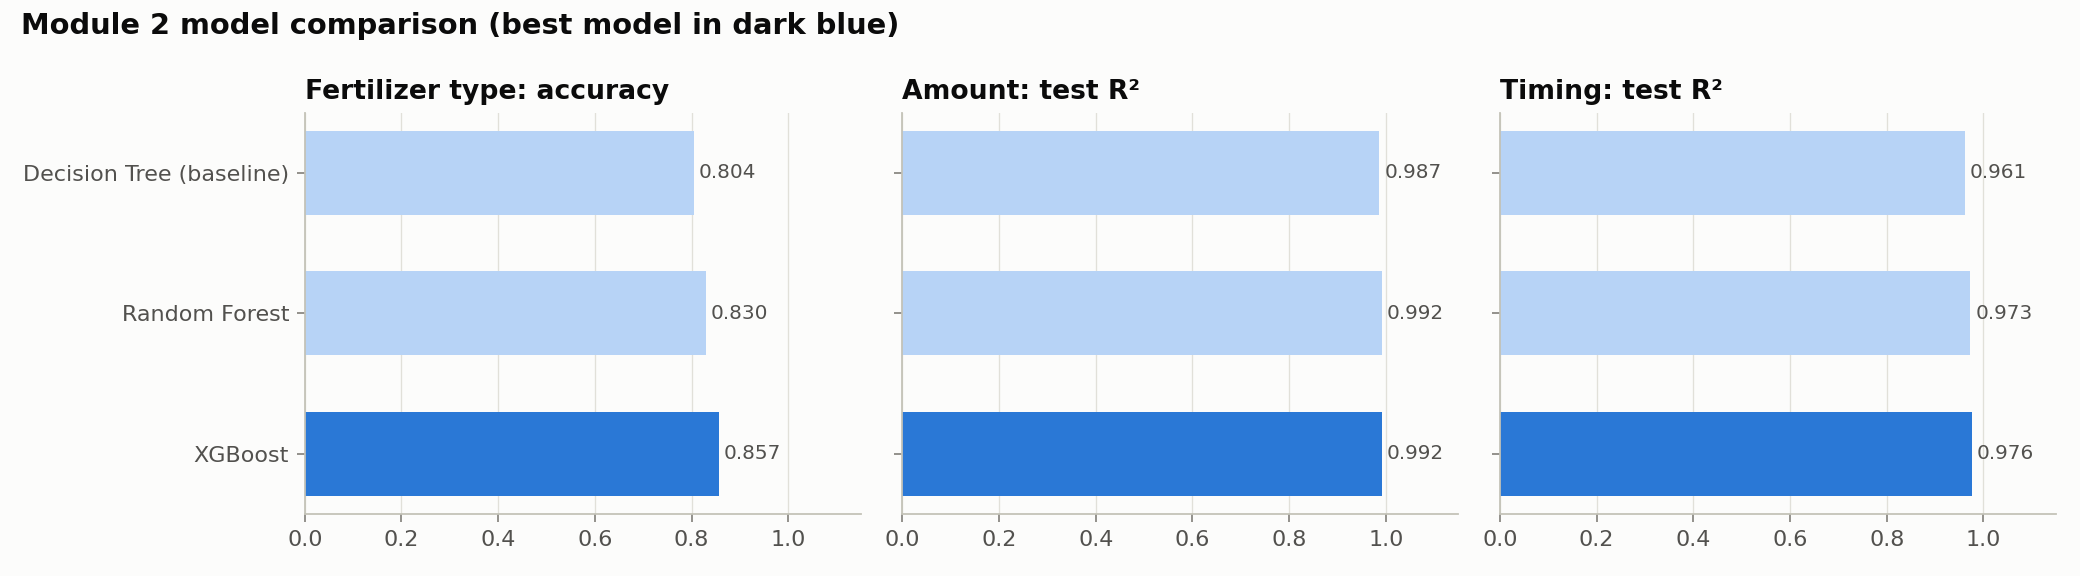

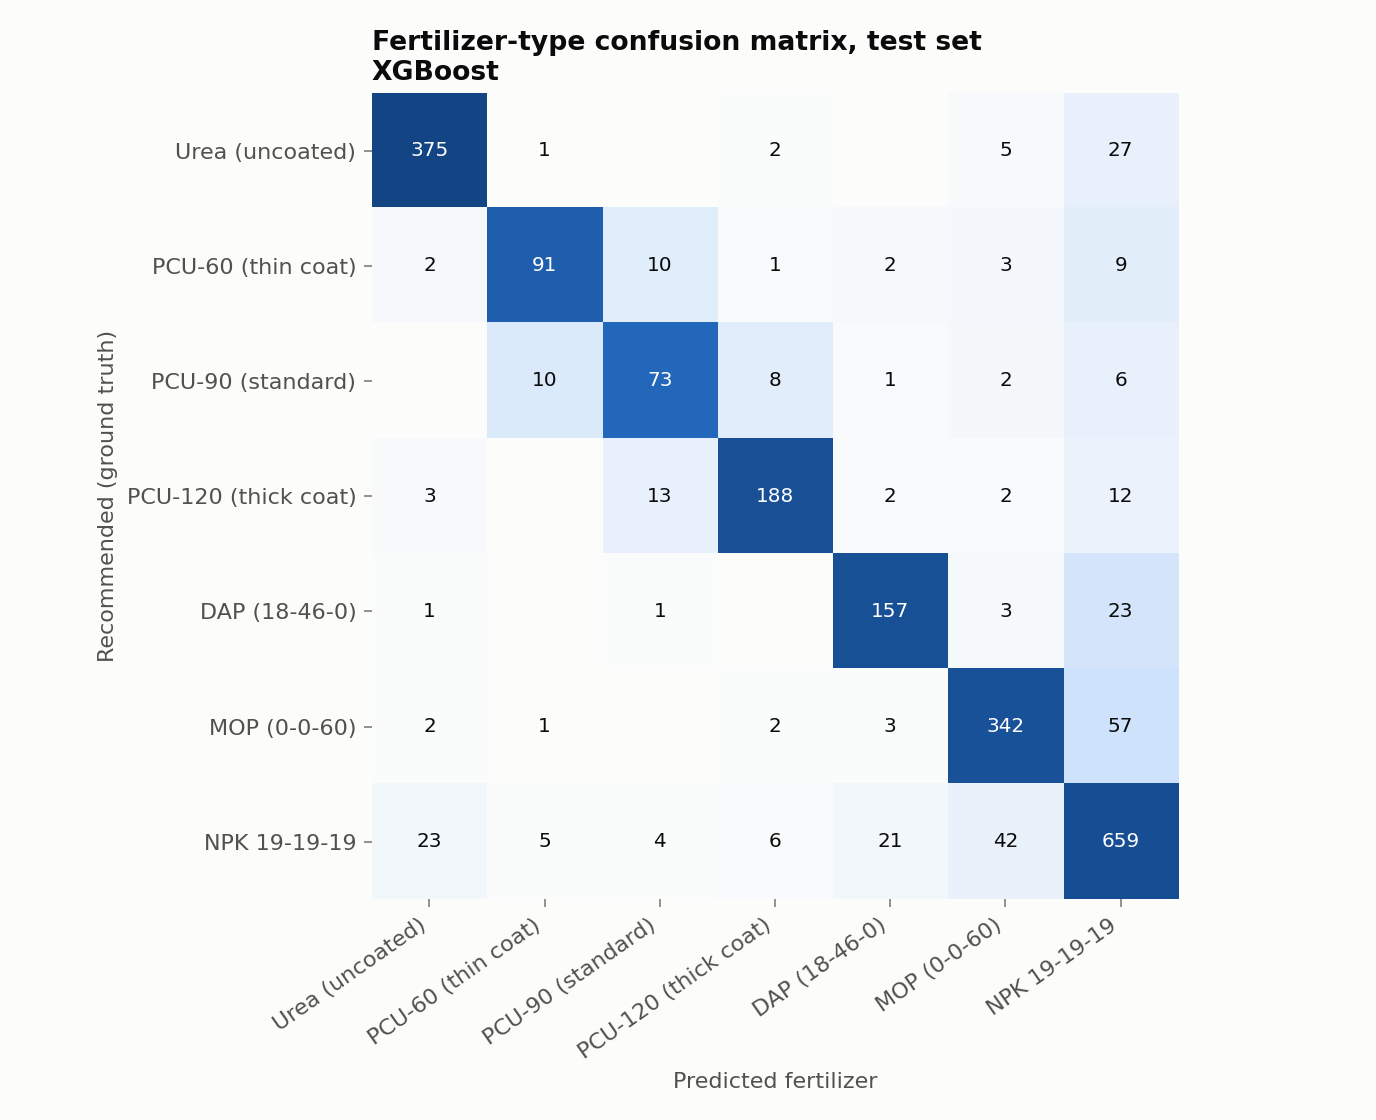

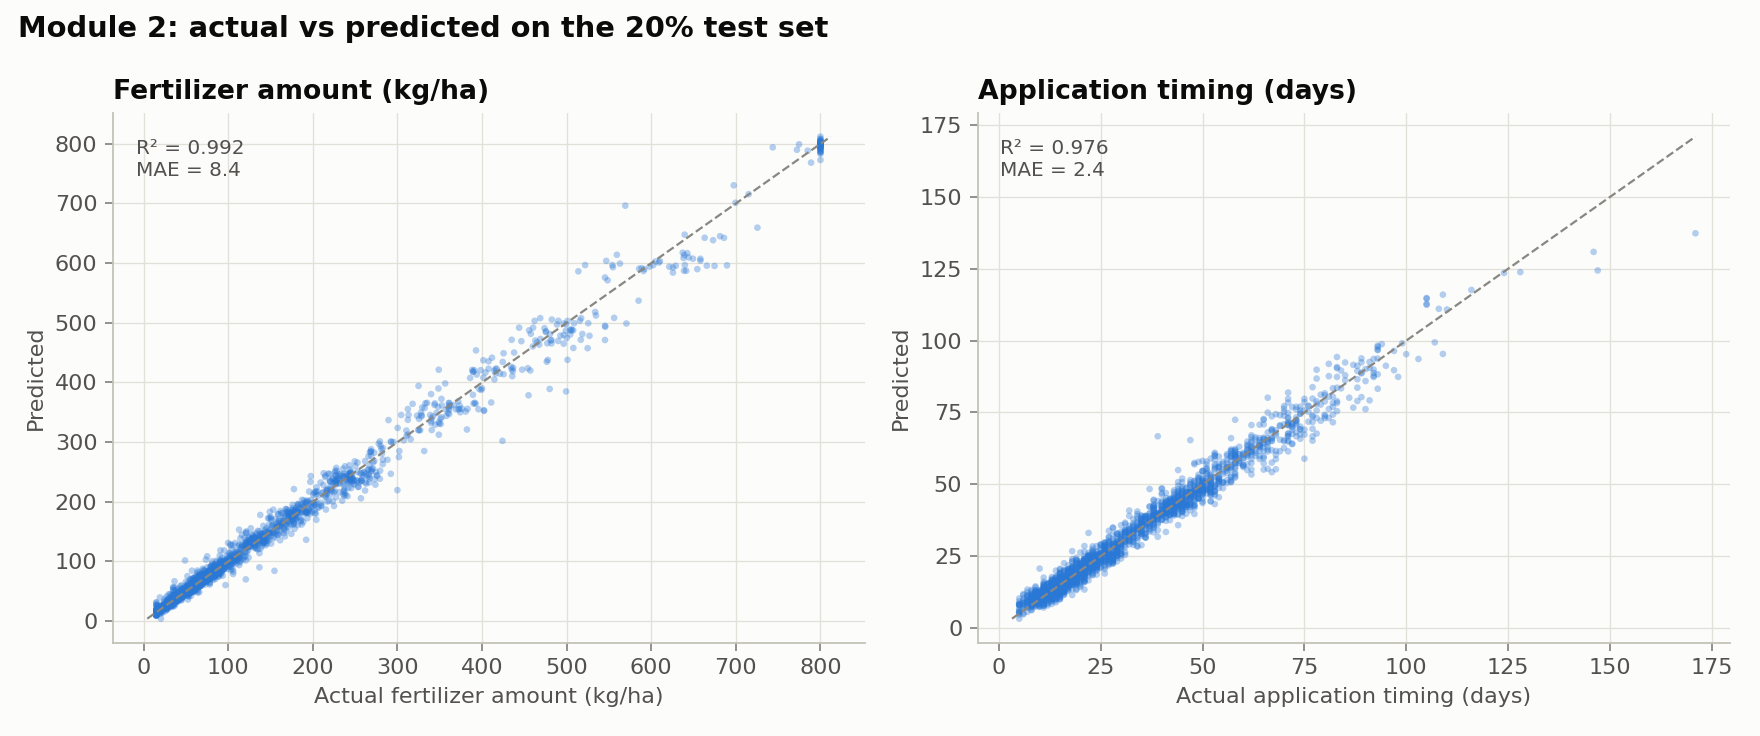

In [12]:
fig("m2_model_comparison.png"); fig("m2_confusion_matrix.png"); fig("m2_actual_vs_predicted.png")

## 5. Evaluation against the existing static system
The existing approach applies the manufacturer's rating, which assumes 25 °C lab conditions. We give every system the
same recommended product and compare amount and timing errors on the test set.

,application_timing MAE,fertilizer_amount MAE,application_timing_coated_urea MAE
Existing static system,9.225,12.622,22.361
ML without Module 1,4.415,8.975,8.446
Proposed dual-module system,2.383,8.412,3.971


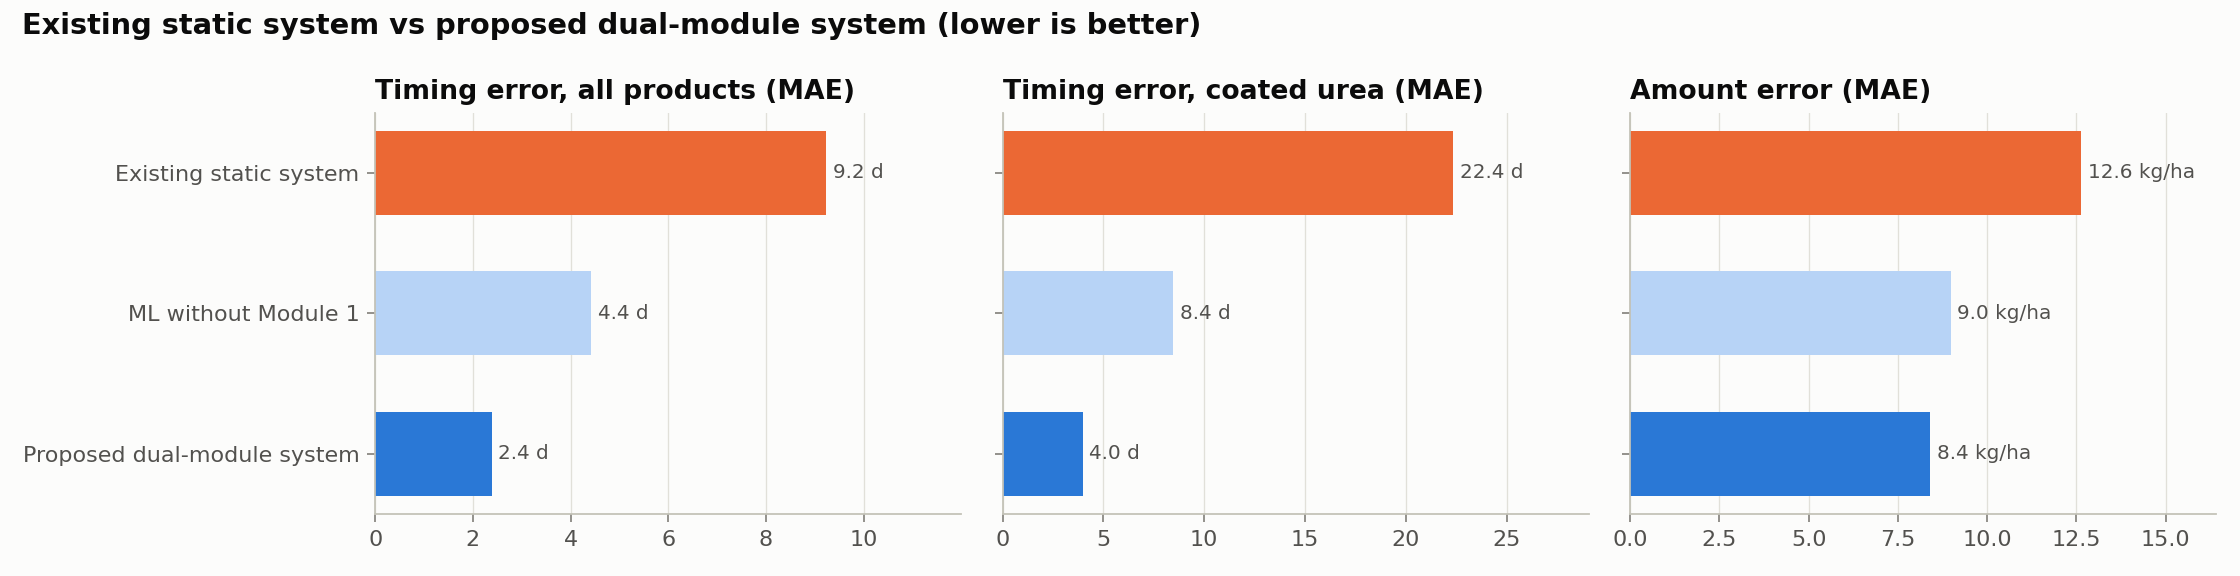

In [13]:
cmp = m2["system_comparison"]
display(pd.DataFrame({k: {s: v["MAE"] for s, v in c.items()} for k, c in cmp.items()}).rename(
    columns=lambda c: c + " MAE"))
fig("system_comparison.png")

For coated urea, the static rating mistimes the next application by about 22 days on average. The dual-module
system gets this to about 4 days. Without Module 1 an ML model reaches about 9 days, so the release prediction is
what closes the gap.

## Testing on user inputs
`predict.py` offers the same function from the command line, e.g.
`python predict.py --crop rice --stage sowing --N 62 --P 45 --K 38 --temp 36 --moisture 42 --rainfall 240 --ph 6.2`

In [14]:
system = SmartFertilizerSystem()
cases = [("Hot, wet rice", "rice", "sowing", 62, 45, 38, dict(soil_temperature=36, soil_moisture=42, rainfall=240, soil_pH=6.2)),
         ("Cool, dry maize", "maize", "sowing", 62, 48, 22, dict(soil_temperature=18, soil_moisture=14, rainfall=45, soil_pH=6.8)),
         ("Cotton, flowering", "cotton", "flowering", 102, 40, 18, dict(soil_temperature=31, soil_moisture=26, rainfall=90, soil_pH=7.1)),
         ("Out-of-range input", "rice", "sowing", 30, 45, 38, dict(soil_temperature=52, soil_moisture=42, rainfall=240, soil_pH=6.2))]
rows = []
for name, crop, stage, n, p, k, field in cases:
    r = system.recommend(field, crop, stage, n, p, k)
    rows.append({"field": name, "90-day PCU lasts (d)": round(r["module1"]["effective_duration"]),
                 "fertilizer": r["fertilizer_type"], "confidence": f"{r['confidence']:.0%}",
                 "amount (kg/ha)": round(r["fertilizer_amount_kg_ha"]),
                 "next dose in (d)": r["next_application_in_days"], "warnings": "; ".join(r["warnings"])})
pd.DataFrame(rows)

,field,90-day PCU lasts (d),fertilizer,confidence,amount (kg/ha),next dose in (d),warnings
0,"Hot, wet rice",41,PCU-120 (thick coat),71%,246,46,
1,"Cool, dry maize",144,PCU-60 (thin coat),94%,223,92,
2,"Cotton, flowering",66,Urea (uncoated),59%,204,11,
3,Out-of-range input,15,NPK 19-19-19,65%,294,8,soil_temperature=52 is outside the training ra...


## Conclusion
- **Module 1** predicts field release from weather, soil and coating with R² ≈ 0.98 (rate) and 0.99 (cumulative),
  replacing the fixed "90-day" label with a condition-specific estimate.
- **Module 2** (XGBoost / Random Forest) recommends the product with accuracy close to the label-noise ceiling. It sizes
  the dose (R² 0.99) and times the next application (R² 0.97) for the chosen product.
- **Integration matters.** Feeding Module 1 into Module 2 lifts coated-urea grade accuracy from 71% to 80%. It also cuts
  timing error from about 22 days to about 4 days compared with the static manufacturer rating.

**Limitations.** Release behaviour and labels are simulated from literature relationships, not measured in the field.
Soil temperature and moisture are derived from air climate. Inputs outside the training range are extrapolations
(the system flags them). Next steps: calibrate Module 1 with lysimeter or incubation data, and add live weather APIs.